# 19 · Final model evaluation

## Purpose

Evaluate the CV-selected model and calibrator exactly once on the stratified internal holdout that remained untouched throughout selection.

## Method

Fit the model on a development subset of the training split, fit the selected calibrator on a separate calibration subset, then compute discrimination, calibration, confusion matrix, and capacity-constrained costs on the final holdout. Compare ROC-AUC/PR-AUC against random/prevalence baselines and Brier/log loss against a constant-prevalence predictor before export.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

The final holdout is internal and random-stratified because event timestamps are unavailable. Do not use these results to retune the model or calibrator.

## References

Metric definitions: https://scikit-learn.org/stable/modules/model_evaluation.html


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '19 · Final model evaluation')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 19 · Final model evaluation


One-time internal final holdout evaluation:


,value
roc_auc,0.589481
pr_auc,0.55606
brier_score,0.243089
log_loss,0.679141
expected_calibration_error,0.001805
holdout_prevalence,0.4746
constant_prevalence_brier,0.249355
constant_prevalence_log_loss,0.691856
threshold,0.5
precision_at_threshold,0.554684


,strategy,capacity_percent,capacity_rows,review_count,false_positive_cost_assumption,false_negative_cost_assumption,review_cost_assumption,expected_decision_cost,false_positives,false_negatives,return_cases_identified,precision_at_k,recall_at_k,count_type,roc_auc,pr_auc,brier_score,log_loss
0,random,5.0,2000,2000,1.0,5.0,0.25,91660.0,1040,18024,960,0.480000,0.050569,observed on labeled validation data,0.589481,0.55606,0.243308,0.679597
1,probability_only,5.0,2000,2000,1.0,5.0,0.25,89758.0,723,17707,1277,0.638500,0.067267,observed on labeled validation data,0.589481,0.55606,0.243308,0.679597
2,fixed_threshold,5.0,2000,2000,1.0,5.0,0.25,89758.0,723,17707,1277,0.638500,0.067267,observed on labeled validation data,0.589481,0.55606,0.243308,0.679597
3,cost_sensitive,5.0,2000,2000,1.0,5.0,0.25,89758.0,723,17707,1277,0.638500,0.067267,observed on labeled validation data,0.589481,0.55606,0.243308,0.679597
4,calibration_aware_cost_sensitive,5.0,2000,2000,1.0,5.0,0.25,89758.0,723,17707,1277,0.638500,0.067267,observed on labeled validation data,0.589481,0.55606,0.243089,0.679141
5,uncertainty_aware,5.0,2000,2000,1.0,5.0,0.25,91540.0,1020,18004,980,0.490000,0.051622,observed on labeled validation data,0.589481,0.55606,0.243089,0.679141
6,random,10.0,4000,4000,1.0,5.0,0.25,88478.0,2093,17077,1907,0.476750,0.100453,observed on labeled validation data,0.589481,0.55606,0.243308,0.679597
7,probability_only,10.0,4000,4000,1.0,5.0,0.25,85094.0,1529,16513,2471,0.617750,0.130162,observed on labeled validation data,0.589481,0.55606,0.243308,0.679597
8,fixed_threshold,10.0,4000,4000,1.0,5.0,0.25,85094.0,1529,16513,2471,0.617750,0.130162,observed on labeled validation data,0.589481,0.55606,0.243308,0.679597
9,cost_sensitive,10.0,4000,4000,1.0,5.0,0.25,85094.0,1529,16513,2471,0.617750,0.130162,observed on labeled validation data,0.589481,0.55606,0.243308,0.679597


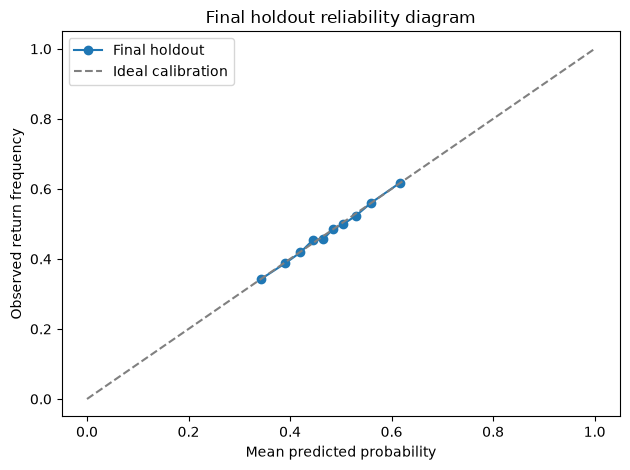

In [2]:
from returnwise.calibration import ProbabilityCalibrator, expected_calibration_error
from returnwise.decision import evaluate_review_strategies
from returnwise.models import fit_best_model, _probabilities
from returnwise.research_state import load_state, save_state
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, f1_score, log_loss, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

state = load_state()
X_train, y_train = state['X_train'], state['y_train']
X_final, y_final = state['X_final'], state['y_final']
x_base, x_cal, y_base, y_cal = train_test_split(X_train, y_train, test_size=0.25, random_state=2718, stratify=y_train)
params = (state.get('tuning_result') or {}).get('pipeline_parameters') if (state.get('tuning_result') or {}).get('model') == state['selected_model'] else None
final_model = fit_best_model(x_base, y_base, state['selected_model'], mode=state.get('experiment_mode', 'quick'), seed=42, parameters=params)
raw_cal = _probabilities(final_model, x_cal)
raw_final = _probabilities(final_model, X_final)
method = state['selected_calibrator']
final_calibrators = {'uncalibrated': None}
if method != 'uncalibrated':
    final_calibrators[method] = ProbabilityCalibrator(method).fit(raw_cal, y_cal)
p_final = raw_final if method == 'uncalibrated' else final_calibrators[method].predict(raw_final)
pred = (p_final >= 0.5).astype(int)
final_metrics = {
    'roc_auc': roc_auc_score(y_final, p_final),
    'pr_auc': average_precision_score(y_final, p_final),
    'brier_score': brier_score_loss(y_final, p_final),
    'log_loss': log_loss(y_final, p_final, labels=[0, 1]),
    'expected_calibration_error': expected_calibration_error(y_final, p_final),
    'holdout_prevalence': float(y_final.mean()),
    'constant_prevalence_brier': brier_score_loss(y_final, np.full(len(y_final), float(y_final.mean()))),
    'constant_prevalence_log_loss': log_loss(y_final, np.full(len(y_final), float(y_final.mean())), labels=[0, 1]),
    'threshold': 0.5,
    'precision_at_threshold': precision_score(y_final, pred, zero_division=0),
    'recall_at_threshold': recall_score(y_final, pred, zero_division=0),
    'f1_at_threshold': f1_score(y_final, pred, zero_division=0),
    'confusion_matrix_tn_fp_fn_tp': confusion_matrix(y_final, pred, labels=[0, 1]).ravel().tolist(),
    'holdout_rows': len(X_final),
    'selected_model': state['selected_model'],
    'selected_calibrator': method,
}
observed_frequency, mean_probability = calibration_curve(y_final, p_final, n_bins=10, strategy='quantile')
final_metrics['reliability_curve'] = [
    {'mean_predicted_probability': float(predicted), 'observed_return_rate': float(observed)}
    for predicted, observed in zip(mean_probability, observed_frequency)
]
print('One-time internal final holdout evaluation:')
display(pd.Series(final_metrics, name='value').to_frame())
final_costs = evaluate_review_strategies(raw_final, y_true=y_final, calibrated_probabilities=p_final)
display(final_costs)
observed, predicted = calibration_curve(y_final, p_final, n_bins=10, strategy='quantile')
plt.plot(predicted, observed, marker='o', label='Final holdout')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Ideal calibration')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed return frequency')
plt.title('Final holdout reliability diagram')
plt.legend()
plt.tight_layout()
plt.show()
state.update({'final_model': final_model, 'final_calibrators': final_calibrators,
              'final_metrics': final_metrics, 'final_raw_probabilities': raw_final,
              'final_probabilities': p_final, 'final_costs': final_costs})
from returnwise.experiments import log_experiment
log_experiment('One-time internal final holdout evaluation', None,
               {'metrics': final_metrics, 'costs': final_costs.to_dict(orient='records')},
               {'selected_model': state['selected_model'], 'selected_calibrator': method,
                'holdout_rows': len(X_final), 'temporal_validation': False})
save_state(state)
